In [124]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline

from sklearn.linear_model import LogisticRegression
from sklearn.neighbors import KNeighborsClassifier
from sklearn.tree import DecisionTreeClassifier

from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    confusion_matrix,
    classification_report,
    roc_auc_score,
    ConfusionMatrixDisplay
)

import joblib

In [125]:
df = pd.read_csv("/bs140513_032310.csv.zip")

print(df.head())
print(df.shape)
print(df.columns)

   step       customer  age gender zipcodeOri       merchant zipMerchant  \
0     0  'C1093826151'  '4'    'M'    '28007'   'M348934600'     '28007'   
1     0   'C352968107'  '2'    'M'    '28007'   'M348934600'     '28007'   
2     0  'C2054744914'  '4'    'F'    '28007'  'M1823072687'     '28007'   
3     0  'C1760612790'  '3'    'M'    '28007'   'M348934600'     '28007'   
4     0   'C757503768'  '5'    'M'    '28007'   'M348934600'     '28007'   

              category  amount  fraud  
0  'es_transportation'    4.55      0  
1  'es_transportation'   39.68      0  
2  'es_transportation'   26.89      0  
3  'es_transportation'   17.25      0  
4  'es_transportation'   35.72      0  
(594643, 10)
Index(['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant',
       'zipMerchant', 'category', 'amount', 'fraud'],
      dtype='object')


In [126]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 594643 entries, 0 to 594642
Data columns (total 10 columns):
 #   Column       Non-Null Count   Dtype  
---  ------       --------------   -----  
 0   step         594643 non-null  int64  
 1   customer     594643 non-null  object 
 2   age          594643 non-null  object 
 3   gender       594643 non-null  object 
 4   zipcodeOri   594643 non-null  object 
 5   merchant     594643 non-null  object 
 6   zipMerchant  594643 non-null  object 
 7   category     594643 non-null  object 
 8   amount       594643 non-null  float64
 9   fraud        594643 non-null  int64  
dtypes: float64(1), int64(2), object(7)
memory usage: 45.4+ MB


In [127]:
df.describe()

,step,amount,fraud
count,594643.000000,594643.000000,594643.000000
mean,94.986827,37.890135,0.012108
std,51.053632,111.402831,0.109369
min,0.000000,0.000000,0.000000
25%,52.000000,13.740000,0.000000
50%,97.000000,26.900000,0.000000
75%,139.000000,42.540000,0.000000
max,179.000000,8329.960000,1.000000


In [128]:
df["fraud"].value_counts()

,count
fraud,
0,587443
1,7200


In [129]:
df["fraud"].value_counts(normalize=True) * 100

,proportion
fraud,
0,98.789189
1,1.210811


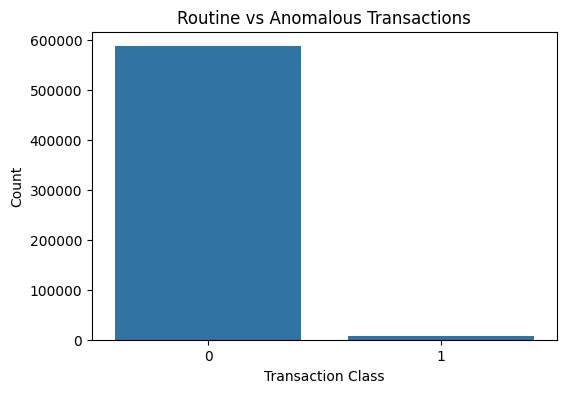

In [130]:
plt.figure(figsize=(6,4))

sns.countplot(data=df, x="fraud")

plt.title("Routine vs Anomalous Transactions")
plt.xlabel("Transaction Class")
plt.ylabel("Count")
plt.show()

In [131]:
df.isnull().sum()

,0
step,0
customer,0
age,0
gender,0
zipcodeOri,0
merchant,0
zipMerchant,0
category,0
amount,0
fraud,0


In [132]:
missing = df.isnull().sum()

missing_percentage = (
    missing / len(df) * 100
).sort_values(ascending=False)

print(missing_percentage)

step           0.0
customer       0.0
age            0.0
gender         0.0
zipcodeOri     0.0
merchant       0.0
zipMerchant    0.0
category       0.0
amount         0.0
fraud          0.0
dtype: float64


In [133]:
missing = df.isnull().sum()

missing_percentage = (
    missing / len(df) * 100
).sort_values(ascending=False)

print(missing_percentage)

step           0.0
customer       0.0
age            0.0
gender         0.0
zipcodeOri     0.0
merchant       0.0
zipMerchant    0.0
category       0.0
amount         0.0
fraud          0.0
dtype: float64


In [134]:
df = df.drop_duplicates()

In [135]:
print(df.shape)

(594643, 10)


In [136]:
merchant_frequency = df["merchant"].value_counts()

df["merchant_frequency"] = (
    df["merchant"].map(merchant_frequency)
)

In [137]:
df[["merchant", "merchant_frequency"]].head()

,merchant,merchant_frequency
0,'M348934600',205426
1,'M348934600',205426
2,'M1823072687',299693
3,'M348934600',205426
4,'M348934600',205426


In [138]:
df[["merchant", "merchant_frequency"]].head()

,merchant,merchant_frequency
0,'M348934600',205426
1,'M348934600',205426
2,'M1823072687',299693
3,'M348934600',205426
4,'M348934600',205426


In [139]:
df["customer_avg_amount"] = (
    df.groupby("customer")["amount"]
      .transform("mean")
)

In [140]:
df["customer_avg_amount"] = (
    df.groupby("customer")["amount"]
      .transform("mean")
)

In [141]:
df["amount_deviation"] = (
    df["amount"] - df["customer_avg_amount"]
)

In [142]:
df["time_period"] = df["step"] % 24

In [143]:
df["is_night"] = (
    (df["time_period"] < 6) |
    (df["time_period"] >= 22)
).astype(int)

In [144]:
df["customer_transaction_count"] = (
    df.groupby("customer")["customer"]
      .transform("count")
)

In [145]:
y = df["fraud"]

In [146]:
features = [
    "amount",
    "step",
    "transaction_frequency",
    "customer_avg_amount",
    "amount_deviation",
    "amount_ratio",
    "customer_transaction_count",
    "is_night",
    "category",
    "merchant"
]

In [147]:
target = "fraud"

In [148]:
# ==========================================
# FEATURE ENGINEERING
# ==========================================

# 1. Merchant frequency
merchant_frequency = df["merchant"].value_counts()
df["merchant_frequency"] = df["merchant"].map(merchant_frequency)


# 2. Category frequency
category_frequency = df["category"].value_counts()
df["category_frequency"] = df["category"].map(category_frequency)


# 3. Customer average transaction amount
df["customer_avg_amount"] = (
    df.groupby("customer")["amount"]
      .transform("mean")
)


# 4. Transaction frequency for each customer
df["transaction_frequency"] = (
    df.groupby("customer")["customer"]
      .transform("count")
)


# 5. Amount deviation from customer's average
df["amount_deviation"] = (
    df["amount"] - df["customer_avg_amount"]
)


# 6. Amount ratio
df["amount_ratio"] = (
    df["amount"] /
    (df["customer_avg_amount"] + 0.01)
)


# 7. Customer transaction count
df["customer_transaction_count"] = (
    df.groupby("customer")["customer"]
      .transform("count")
)


# 8. Time period
df["time_period"] = df["step"] % 24


# 9. Night-time indicator
df["is_night"] = (
    (df["time_period"] < 6) |
    (df["time_period"] >= 22)
).astype(int)


print("Feature engineering completed!")
print(df.shape)

print("\nNew columns:")
print([
    "merchant_frequency",
    "category_frequency",
    "customer_avg_amount",
    "transaction_frequency",
    "amount_deviation",
    "amount_ratio",
    "customer_transaction_count",
    "time_period",
    "is_night"
])

Feature engineering completed!
(594643, 19)

New columns:
['merchant_frequency', 'category_frequency', 'customer_avg_amount', 'transaction_frequency', 'amount_deviation', 'amount_ratio', 'customer_transaction_count', 'time_period', 'is_night']


In [149]:
print(df.columns.tolist())

['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category', 'amount', 'fraud', 'merchant_frequency', 'customer_avg_amount', 'amount_deviation', 'time_period', 'is_night', 'customer_transaction_count', 'category_frequency', 'transaction_frequency', 'amount_ratio']


In [150]:
features = [
    "amount",
    "step",
    "transaction_frequency",
    "customer_avg_amount",
    "amount_deviation",
    "amount_ratio",
    "customer_transaction_count",
    "merchant_frequency",
    "category_frequency",
    "is_night",
    "category"
]

target = "fraud"

In [151]:
X = df[features]
y = df[target]

print("X shape:", X.shape)
print("y shape:", y.shape)

X shape: (594643, 11)
y shape: (594643,)


In [152]:
X.head()

,amount,step,transaction_frequency,customer_avg_amount,amount_deviation,amount_ratio,customer_transaction_count,merchant_frequency,category_frequency,is_night,category
0,4.55,0,167,28.240719,-23.690719,0.161058,167,205426,505119,1,'es_transportation'
1,39.68,0,169,32.661361,7.018639,1.214519,169,205426,505119,1,'es_transportation'
2,26.89,0,65,41.443692,-14.553692,0.648676,65,299693,505119,1,'es_transportation'
3,17.25,0,171,30.338772,-13.088772,0.568392,171,205426,505119,1,'es_transportation'
4,35.72,0,145,31.696759,4.023241,1.126574,145,205426,505119,1,'es_transportation'


In [153]:
X = df[features]
y = df[target]

In [154]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42,
    stratify=y
)

In [155]:
numeric_features = [
    "amount",
    "step",
    "transaction_frequency",
    "customer_avg_amount",
    "amount_deviation",
    "amount_ratio",
    "customer_transaction_count",
    "is_night"
]

categorical_features = [
    "category",
    "merchant"
]

In [156]:
preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(
                handle_unknown="ignore"
            ),
            categorical_features
        )
    ]
)

In [157]:
print("Shape:", df.shape)
print("\nColumns:")
print(df.columns.tolist())

Shape: (594643, 19)

Columns:
['step', 'customer', 'age', 'gender', 'zipcodeOri', 'merchant', 'zipMerchant', 'category', 'amount', 'fraud', 'merchant_frequency', 'customer_avg_amount', 'amount_deviation', 'time_period', 'is_night', 'customer_transaction_count', 'category_frequency', 'transaction_frequency', 'amount_ratio']


In [158]:
from sklearn.model_selection import train_test_split

# Separate target
target = "fraud"

# Split the original dataframe first
train_df, test_df = train_test_split(
    df,
    test_size=0.20,
    random_state=42,
    stratify=df[target]
)

print("Training shape:", train_df.shape)
print("Testing shape:", test_df.shape)

Training shape: (475714, 19)
Testing shape: (118929, 19)


In [159]:
# ==========================================
# BEHAVIORAL FEATURE ENGINEERING
# ==========================================

# ---------- CUSTOMER FEATURES ----------

# Customer average amount calculated ONLY from training data
customer_avg = train_df.groupby("customer")["amount"].mean()

train_df["customer_avg_amount"] = (
    train_df["customer"].map(customer_avg)
)

test_df["customer_avg_amount"] = (
    test_df["customer"].map(customer_avg)
)

# Fill unseen customers in test data
test_df["customer_avg_amount"] = (
    test_df["customer_avg_amount"]
    .fillna(train_df["amount"].mean())
)


# Customer transaction frequency
customer_frequency = train_df["customer"].value_counts()

train_df["transaction_frequency"] = (
    train_df["customer"].map(customer_frequency)
)

test_df["transaction_frequency"] = (
    test_df["customer"].map(customer_frequency)
    .fillna(0)
)


# ---------- MERCHANT FEATURES ----------

merchant_frequency = train_df["merchant"].value_counts()

train_df["merchant_frequency"] = (
    train_df["merchant"].map(merchant_frequency)
)

test_df["merchant_frequency"] = (
    test_df["merchant"].map(merchant_frequency)
    .fillna(0)
)


# ---------- CATEGORY FEATURES ----------

category_frequency = train_df["category"].value_counts()

train_df["category_frequency"] = (
    train_df["category"].map(category_frequency)
)

test_df["category_frequency"] = (
    test_df["category"].map(category_frequency)
    .fillna(0)
)


# ---------- AMOUNT FEATURES ----------

train_df["amount_deviation"] = (
    train_df["amount"] -
    train_df["customer_avg_amount"]
)

test_df["amount_deviation"] = (
    test_df["amount"] -
    test_df["customer_avg_amount"]
)


train_df["amount_ratio"] = (
    train_df["amount"] /
    (train_df["customer_avg_amount"] + 0.01)
)

test_df["amount_ratio"] = (
    test_df["amount"] /
    (test_df["customer_avg_amount"] + 0.01)
)


# ---------- TIME FEATURES ----------

train_df["time_period"] = train_df["step"] % 24
test_df["time_period"] = test_df["step"] % 24


train_df["is_night"] = (
    (train_df["time_period"] < 6) |
    (train_df["time_period"] >= 22)
).astype(int)

test_df["is_night"] = (
    (test_df["time_period"] < 6) |
    (test_df["time_period"] >= 22)
).astype(int)


# ---------- CUSTOMER TRANSACTION COUNT ----------

train_df["customer_transaction_count"] = (
    train_df["customer"].map(customer_frequency)
)

test_df["customer_transaction_count"] = (
    test_df["customer"].map(customer_frequency)
    .fillna(0)
)

print("Feature engineering completed!")

Feature engineering completed!


In [160]:
features = [
    "amount",
    "step",
    "transaction_frequency",
    "customer_avg_amount",
    "amount_deviation",
    "amount_ratio",
    "customer_transaction_count",
    "merchant_frequency",
    "category_frequency",
    "is_night",
    "category"
]

X_train = train_df[features]
y_train = train_df["fraud"]

X_test = test_df[features]
y_test = test_df["fraud"]

print("X_train:", X_train.shape)
print("X_test:", X_test.shape)
print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

X_train: (475714, 11)
X_test: (118929, 11)
y_train: (475714,)
y_test: (118929,)


In [161]:
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import StandardScaler, OneHotEncoder

numeric_features = [
    "amount",
    "step",
    "transaction_frequency",
    "customer_avg_amount",
    "amount_deviation",
    "amount_ratio",
    "customer_transaction_count",
    "merchant_frequency",
    "category_frequency",
    "is_night"
]

categorical_features = [
    "category"
]

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numeric_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessing ready!")

Preprocessing ready!


In [162]:
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression

logistic_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            LogisticRegression(
                max_iter=1000,
                class_weight="balanced"
            )
        )
    ]
)

print("Training Logistic Regression...")

logistic_model.fit(
    X_train,
    y_train
)

print("Training completed!")

Training Logistic Regression...
Training completed!


In [163]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score
)

logistic_pred = logistic_model.predict(X_test)

print("Logistic Regression Results")
print("--------------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, logistic_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        logistic_pred,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        logistic_pred,
        zero_division=0
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        logistic_pred,
        zero_division=0
    )
)

Logistic Regression Results
--------------------------------
Accuracy: 0.964163492503931
Precision: 0.25
Recall: 0.9798611111111111
F1 Score: 0.39836250705815923


In [164]:
from sklearn.tree import DecisionTreeClassifier
from sklearn.pipeline import Pipeline

tree_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            DecisionTreeClassifier(
                max_depth=8,
                class_weight="balanced",
                random_state=42
            )
        )
    ]
)

print("Training Decision Tree...")

tree_model.fit(
    X_train,
    y_train
)

print("Decision Tree training completed!")

Training Decision Tree...
Decision Tree training completed!


In [165]:
tree_pred = tree_model.predict(X_test)

print("Decision Tree Results")
print("----------------------------")

print(
    "Accuracy:",
    accuracy_score(y_test, tree_pred)
)

print(
    "Precision:",
    precision_score(
        y_test,
        tree_pred,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_test,
        tree_pred,
        zero_division=0
    )
)

print(
    "F1 Score:",
    f1_score(
        y_test,
        tree_pred,
        zero_division=0
    )
)

Decision Tree Results
----------------------------
Accuracy: 0.9733538497759168
Precision: 0.30945558739255014
Recall: 0.975
F1 Score: 0.4698009034632759


In [166]:
from sklearn.neighbors import KNeighborsClassifier
from sklearn.pipeline import Pipeline

# Use a smaller sample for KNN
knn_train = train_df.sample(
    n=50000,
    random_state=42
)

knn_test = test_df.sample(
    n=10000,
    random_state=42
)

X_knn_train = knn_train[features]
y_knn_train = knn_train["fraud"]

X_knn_test = knn_test[features]
y_knn_test = knn_test["fraud"]

print("KNN training data:", X_knn_train.shape)
print("KNN testing data:", X_knn_test.shape)

KNN training data: (50000, 11)
KNN testing data: (10000, 11)


In [167]:
knn_model = Pipeline(
    steps=[
        ("preprocessor", preprocessor),
        (
            "classifier",
            KNeighborsClassifier(
                n_neighbors=5,
                n_jobs=-1
            )
        )
    ]
)

print("Training KNN...")

knn_model.fit(
    X_knn_train,
    y_knn_train
)

print("KNN training completed!")

Training KNN...
KNN training completed!


In [168]:
knn_pred = knn_model.predict(X_knn_test)

print("KNN Results")
print("----------------------------")

print(
    "Accuracy:",
    accuracy_score(
        y_knn_test,
        knn_pred
    )
)

print(
    "Precision:",
    precision_score(
        y_knn_test,
        knn_pred,
        zero_division=0
    )
)

print(
    "Recall:",
    recall_score(
        y_knn_test,
        knn_pred,
        zero_division=0
    )
)

print(
    "F1 Score:",
    f1_score(
        y_knn_test,
        knn_pred,
        zero_division=0
    )
)

KNN Results
----------------------------
Accuracy: 0.9945
Precision: 0.8651685393258427
Recall: 0.6416666666666667
F1 Score: 0.7368421052631579


In [169]:
import pandas as pd

results_df = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_knn_test, knn_pred)
    ],
    "Precision": [
        precision_score(y_test, logistic_pred, zero_division=0),
        precision_score(y_test, tree_pred, zero_division=0),
        precision_score(y_knn_test, knn_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, logistic_pred, zero_division=0),
        recall_score(y_test, tree_pred, zero_division=0),
        recall_score(y_knn_test, knn_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, logistic_pred, zero_division=0),
        f1_score(y_test, tree_pred, zero_division=0),
        f1_score(y_knn_test, knn_pred, zero_division=0)
    ]
})

results_df

,Model,Accuracy,Precision,Recall,F1 Score
0,Logistic Regression,0.964163,0.250000,0.979861,0.398363
1,Decision Tree,0.973354,0.309456,0.975000,0.469801
2,KNN,0.994500,0.865169,0.641667,0.736842


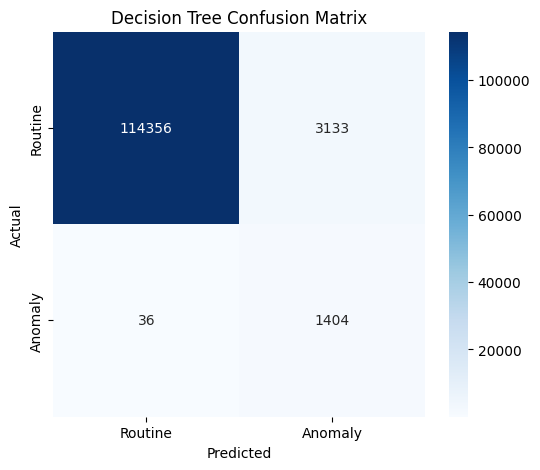

In [170]:
from sklearn.metrics import confusion_matrix
import matplotlib.pyplot as plt
import seaborn as sns

cm = confusion_matrix(y_test, tree_pred)

plt.figure(figsize=(6, 5))

sns.heatmap(
    cm,
    annot=True,
    fmt="d",
    cmap="Blues",
    xticklabels=["Routine", "Anomaly"],
    yticklabels=["Routine", "Anomaly"]
)

plt.xlabel("Predicted")
plt.ylabel("Actual")
plt.title("Decision Tree Confusion Matrix")

plt.show()

In [171]:
# ==========================================
# FALSE POSITIVE ANALYSIS
# ==========================================

# Create a copy of test data
analysis_df = test_df.copy()

# Add predictions
analysis_df["prediction"] = tree_pred

# False positives:
# Actual = 0 (Routine)
# Predicted = 1 (Anomaly)

false_positives = analysis_df[
    (analysis_df["fraud"] == 0) &
    (analysis_df["prediction"] == 1)
].copy()

print("Number of False Positives:", len(false_positives))

print("\nFalse Positive Percentage:")
print(
    round(
        len(false_positives) /
        len(test_df) * 100,
        2
    ),
    "%"
)

print("\nFalse Positive Sample:")
display(
    false_positives[
        [
            "amount",
            "step",
            "category",
            "merchant_frequency",
            "transaction_frequency",
            "customer_avg_amount",
            "amount_ratio",
            "is_night",
            "fraud",
            "prediction"
        ]
    ].head(10)
)

Number of False Positives: 3133

False Positive Percentage:
2.63 %

False Positive Sample:


,amount,step,category,merchant_frequency,transaction_frequency,customer_avg_amount,amount_ratio,is_night,fraud,prediction
251303,48.97,84,'es_wellnessandbeauty',1293,146,35.398014,1.383020,0,0,1
6267,38.90,2,'es_hyper',4886,64,41.900156,0.928176,1,0,1
472123,67.67,146,'es_barsandrestaurants',5066,33,207.202121,0.326574,1,0,1
162678,0.79,57,'es_home',615,138,38.701304,0.020407,0,0,1
413118,25.74,130,'es_wellnessandbeauty',1238,51,37.539608,0.685493,0,0,1
37889,163.40,14,'es_health',2801,115,34.254870,4.768733,0,0,1
223228,4.50,75,'es_health',2801,56,38.678214,0.116314,1,0,1
17065,105.47,6,'es_sportsandtoys',430,24,101.493333,1.039079,0,0,1
84243,29.00,31,'es_hyper',4886,120,39.511333,0.733781,0,0,1
279702,16.03,92,'es_wellnessandbeauty',1508,6,180.096667,0.089003,0,0,1


In [172]:
print("False Positive Amount Statistics")
print("--------------------------------")

print(
    false_positives["amount"].describe()
)

False Positive Amount Statistics
--------------------------------
count    3133.000000
mean       89.651047
std        88.829361
min         0.050000
25%        31.960000
50%        65.830000
75%       128.230000
max      1342.080000
Name: amount, dtype: float64


In [173]:
print("False Positives by Category")
print("----------------------------")

category_fp = (
    false_positives["category"]
    .value_counts()
)

print(category_fp)

False Positives by Category
----------------------------
category
'es_wellnessandbeauty'     737
'es_health'                704
'es_hyper'                 353
'es_sportsandtoys'         293
'es_barsandrestaurants'    288
'es_fashion'               191
'es_otherservices'         148
'es_home'                  143
'es_hotelservices'         136
'es_tech'                  118
'es_travel'                 17
'es_leisure'                 3
'es_contents'                2
Name: count, dtype: int64


In [174]:
print("False Positives by Time")
print("-----------------------")

print(
    false_positives["is_night"]
    .value_counts()
)

print("\n0 = Daytime")
print("1 = Night")

False Positives by Time
-----------------------
is_night
0    2026
1    1107
Name: count, dtype: int64

0 = Daytime
1 = Night


In [175]:
correct_routine = analysis_df[
    (analysis_df["fraud"] == 0) &
    (analysis_df["prediction"] == 0)
].copy()

comparison = pd.DataFrame({
    "False Positives": [
        false_positives["amount"].mean(),
        false_positives["amount_ratio"].mean(),
        false_positives["transaction_frequency"].mean(),
        false_positives["merchant_frequency"].mean()
    ],
    "Correct Routine": [
        correct_routine["amount"].mean(),
        correct_routine["amount_ratio"].mean(),
        correct_routine["transaction_frequency"].mean(),
        correct_routine["merchant_frequency"].mean()
    ]
}, index=[
    "Average Amount",
    "Average Amount Ratio",
    "Average Transaction Frequency",
    "Average Merchant Frequency"
])

comparison

,False Positives,Correct Routine
Average Amount,89.651047,30.325439
Average Amount Ratio,1.982970,0.920104
Average Transaction Frequency,87.654006,126.408680
Average Merchant Frequency,2090.746888,185895.354227


In [176]:
from sklearn.metrics import roc_auc_score, roc_curve
import matplotlib.pyplot as plt

# Probability of anomaly
logistic_prob = logistic_model.predict_proba(X_test)[:, 1]
tree_prob = tree_model.predict_proba(X_test)[:, 1]

# ROC-AUC
logistic_auc = roc_auc_score(y_test, logistic_prob)
tree_auc = roc_auc_score(y_test, tree_prob)

print("ROC-AUC Results")
print("----------------------")
print("Logistic Regression:", logistic_auc)
print("Decision Tree:", tree_auc)

ROC-AUC Results
----------------------
Logistic Regression: 0.9960984349835115
Decision Tree: 0.8734870983193699


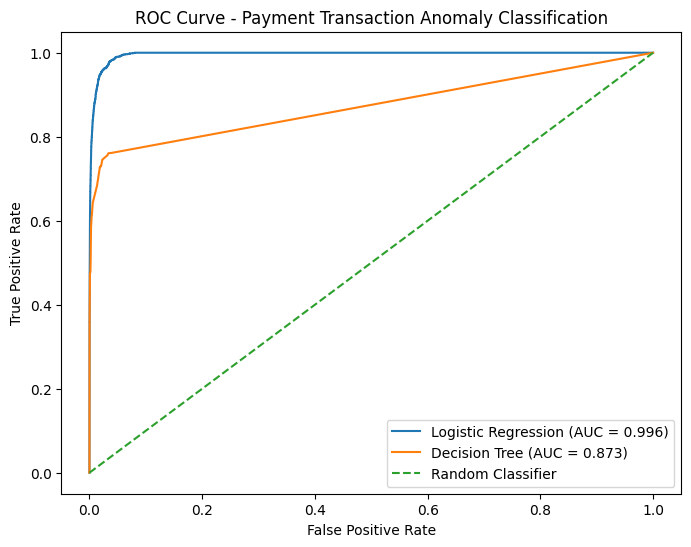

In [177]:
logistic_fpr, logistic_tpr, _ = roc_curve(
    y_test,
    logistic_prob
)

tree_fpr, tree_tpr, _ = roc_curve(
    y_test,
    tree_prob
)

plt.figure(figsize=(8, 6))

plt.plot(
    logistic_fpr,
    logistic_tpr,
    label=f"Logistic Regression (AUC = {logistic_auc:.3f})"
)

plt.plot(
    tree_fpr,
    tree_tpr,
    label=f"Decision Tree (AUC = {tree_auc:.3f})"
)

plt.plot(
    [0, 1],
    [0, 1],
    linestyle="--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("ROC Curve - Payment Transaction Anomaly Classification")
plt.legend()
plt.show()

In [178]:
final_results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "KNN"
    ],
    "Accuracy": [
        accuracy_score(y_test, logistic_pred),
        accuracy_score(y_test, tree_pred),
        accuracy_score(y_knn_test, knn_pred)
    ],
    "Precision": [
        precision_score(y_test, logistic_pred, zero_division=0),
        precision_score(y_test, tree_pred, zero_division=0),
        precision_score(y_knn_test, knn_pred, zero_division=0)
    ],
    "Recall": [
        recall_score(y_test, logistic_pred, zero_division=0),
        recall_score(y_test, tree_pred, zero_division=0),
        recall_score(y_knn_test, knn_pred, zero_division=0)
    ],
    "F1 Score": [
        f1_score(y_test, logistic_pred, zero_division=0),
        f1_score(y_test, tree_pred, zero_division=0),
        f1_score(y_knn_test, knn_pred, zero_division=0)
    ],
    "ROC-AUC": [
        logistic_auc,
        tree_auc,
        "Sample evaluation"
    ]
})

final_results

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.964163,0.250000,0.979861,0.398363,0.996098
1,Decision Tree,0.973354,0.309456,0.975000,0.469801,0.873487
2,KNN,0.994500,0.865169,0.641667,0.736842,Sample evaluation


In [179]:
import joblib

final_model = tree_model

joblib.dump(
    final_model,
    "payment_anomaly_model.pkl"
)

print("Final model saved successfully!")

Final model saved successfully!


In [180]:
from google.colab import files

files.download("payment_anomaly_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [181]:
print("Features used by the model:")
print(features)

print("\nNumber of features:", len(features))

print("\nModel type:")
print(type(tree_model))

Features used by the model:
['amount', 'step', 'transaction_frequency', 'customer_avg_amount', 'amount_deviation', 'amount_ratio', 'customer_transaction_count', 'merchant_frequency', 'category_frequency', 'is_night', 'category']

Number of features: 11

Model type:
<class 'sklearn.pipeline.Pipeline'>


In [182]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nFeature columns:")
print(X_train.columns.tolist())

X_train shape: (475714, 11)
X_test shape: (118929, 11)

Feature columns:
['amount', 'step', 'transaction_frequency', 'customer_avg_amount', 'amount_deviation', 'amount_ratio', 'customer_transaction_count', 'merchant_frequency', 'category_frequency', 'is_night', 'category']


In [183]:
print("Features used by the model:")
print(features)

print("\nNumber of features:", len(features))

print("\nModel type:")
print(type(tree_model))

Features used by the model:
['amount', 'step', 'transaction_frequency', 'customer_avg_amount', 'amount_deviation', 'amount_ratio', 'customer_transaction_count', 'merchant_frequency', 'category_frequency', 'is_night', 'category']

Number of features: 11

Model type:
<class 'sklearn.pipeline.Pipeline'>


In [184]:
print("X_train shape:", X_train.shape)
print("X_test shape:", X_test.shape)

print("\nFeature columns:")
print(X_train.columns.tolist())

X_train shape: (475714, 11)
X_test shape: (118929, 11)

Feature columns:
['amount', 'step', 'transaction_frequency', 'customer_avg_amount', 'amount_deviation', 'amount_ratio', 'customer_transaction_count', 'merchant_frequency', 'category_frequency', 'is_night', 'category']


In [185]:
print("COMPLETE FEATURE LIST")
print()

for i, feature in enumerate(features, start=1):
    print(i, "->", feature)

COMPLETE FEATURE LIST

1 -> amount
2 -> step
3 -> transaction_frequency
4 -> customer_avg_amount
5 -> amount_deviation
6 -> amount_ratio
7 -> customer_transaction_count
8 -> merchant_frequency
9 -> category_frequency
10 -> is_night
11 -> category


In [186]:
import joblib

final_model = {
    "model": tree_model,
    "features": features
}

joblib.dump(final_model, "payment_anomaly_model.pkl")

print("Model + features saved successfully!")

Model + features saved successfully!


In [187]:
from google.colab import files

files.download("payment_anomaly_model.pkl")

<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [188]:
!pip install streamlit

In [189]:
!streamlit --version

Streamlit, version 1.64.0


In [190]:
!pip install -q pyngrok

In [191]:
import os

print(os.path.exists("/content/payment_anomaly_model.pkl"))

True


In [192]:
from google.colab import files

uploaded = files.upload()

Saving payment_anomaly_model (1).pkl to payment_anomaly_model (1) (1).pkl


In [193]:
!pip install -q streamlit pyngrok

In [194]:
import os

print(
    "Model exists:",
    os.path.exists("/content/payment_anomaly_model.pkl")
)

Model exists: True


In [195]:
!pip install -q streamlit pyngrok

In [196]:
for i, feature in enumerate(features, start=1):
    print(f"{i}. {feature}")

1. amount
2. step
3. transaction_frequency
4. customer_avg_amount
5. amount_deviation
6. amount_ratio
7. customer_transaction_count
8. merchant_frequency
9. category_frequency
10. is_night
11. category


In [197]:
print(features)

['amount', 'step', 'transaction_frequency', 'customer_avg_amount', 'amount_deviation', 'amount_ratio', 'customer_transaction_count', 'merchant_frequency', 'category_frequency', 'is_night', 'category']


In [198]:
%%writefile app.py

import streamlit as st
import pandas as pd
import joblib

# Load trained model
model = joblib.load("/content/payment_anomaly_model.pkl")

# Page configuration
st.set_page_config(
    page_title="Payment Transaction Risk AI",
    page_icon="💳",
    layout="centered"
)

st.title("💳 Payment Transaction Risk AI")
st.write("AI-powered transaction anomaly detection")

st.divider()

# User inputs
amount = st.number_input(
    "Transaction Amount",
    min_value=0.0,
    value=1000.0
)

step = st.number_input(
    "Transaction Time / Step",
    min_value=0,
    value=10
)

transaction_frequency = st.number_input(
    "Transaction Frequency",
    min_value=1,
    value=5
)

customer_avg_amount = st.number_input(
    "Customer Average Amount",
    min_value=0.0,
    value=1000.0
)

customer_transaction_count = st.number_input(
    "Customer Transaction Count",
    min_value=1,
    value=5
)

merchant_frequency = st.number_input(
    "Merchant Frequency",
    min_value=1,
    value=100
)

category_frequency = st.number_input(
    "Category Frequency",
    min_value=1,
    value=100
)

category = st.selectbox(
    "Transaction Category",
    [
        "es_barsandrestaurants",
        "es_contents",
        "es_fashion",
        "es_food",
        "es_health",
        "es_home",
        "es_hotelservices",
        "es_hyper",
        "es_leisure",
        "es_otherservices",
        "es_sportsandtoys",
        "es_tech",
        "es_transportation",
        "es_travel",
        "es_wellnessandbeauty"
    ]
)

# Calculate engineered features
amount_deviation = amount - customer_avg_amount

amount_ratio = amount / (customer_avg_amount + 0.01)

time_period = step % 24

is_night = int(
    (time_period < 6) or (time_period >= 22)
)

# Create input dataframe
input_data = pd.DataFrame([{
    "amount": amount,
    "step": step,
    "transaction_frequency": transaction_frequency,
    "customer_avg_amount": customer_avg_amount,
    "amount_deviation": amount_deviation,
    "amount_ratio": amount_ratio,
    "customer_transaction_count": customer_transaction_count,
    "merchant_frequency": merchant_frequency,
    "category_frequency": category_frequency,
    "is_night": is_night,
    "category": category
}])

st.divider()

# Prediction
if st.button("🔍 Check Transaction Risk", use_container_width=True):

    prediction = model.predict(input_data)[0]

    probability = model.predict_proba(input_data)[0][1]

    if prediction == 1:
        st.error("🚨 ANOMALOUS TRANSACTION")
    else:
        st.success("✅ ROUTINE TRANSACTION")

    st.metric(
        "Anomaly Probability",
        f"{probability * 100:.2f}%"
    )

    if probability >= 0.75:
        risk = "HIGH RISK"
    elif probability >= 0.40:
        risk = "MEDIUM RISK"
    else:
        risk = "LOW RISK"

    st.subheader("Risk Level")

    if risk == "HIGH RISK":
        st.error(risk)
    elif risk == "MEDIUM RISK":
        st.warning(risk)
    else:
        st.success(risk)

    st.subheader("Transaction Summary")

    st.write(f"**Amount:** ₹{amount:,.2f}")
    st.write(f"**Transaction Frequency:** {transaction_frequency}")
    st.write(f"**Customer Average Amount:** ₹{customer_avg_amount:,.2f}")
    st.write(f"**Night Transaction:** {'Yes' if is_night else 'No'}")

Overwriting app.py


In [199]:
!ls -l app.py

-rw-r--r-- 1 root root 3281 Sep 30 13:55 app.py


In [200]:
!streamlit run app.py &> streamlit.log &

In [201]:
!cat streamlit.log

In [212]:
!ngrok config add-authtoken "3K396wTrhYJTArnppgfOyic0NMo_66sG29ENmcTQpjFXqfbbq"

Authtoken saved to configuration file: /root/.config/ngrok/ngrok.yml


In [215]:
from pyngrok import ngrok

ngrok.kill()

public_url = ngrok.connect(8501, "http")

print("Streamlit URL:")
print(public_url)

Streamlit URL:
NgrokTunnel: "https://reshoot-usable-prissy.ngrok-free.dev" -> "http://localhost:8501"
